In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import shutil
import skrf as rf
import subprocess
from pathlib import Path
from scipy.constants import c
from scipy.optimize import brentq
from skrf.mathFunctions import db_2_mag, mag_2_db
from skrf.media import CPW
from skrf.taper import Klopfenstein, Taper1D

In [2]:
# CPW geometry and substrate (all lengths in m)
W = 40e-6
S1 = 25e-6
H = 500e-6
EP_R = 11.7

# Taper specification
Z_TARGET = 36.0
F_C = 9e9               # lower passband edge
GAMMA_M_DB = -30.0      # passband reflection ripple
N_SECTIONS = 20

freq = rf.Frequency(0.1, 30, 401, 'GHz')
i_c = np.argmin(np.abs(freq.f - F_C))

# Zero-thickness PEC: t=None, rho=None. Lossless dielectric: tand=0. Air backside.
cpw_kw = dict(frequency=freq, w=W, h=H, ep_r=EP_R, t=None, rho=None, tand=0,
              diel='frequencyinvariant', has_metal_backside=False)


def z0_of_s(s):
    return CPW(s=s, **cpw_kw).z0_characteristic[i_c].real


def s_of_z0(z):
    return brentq(lambda s: z0_of_s(s) - z, 0.5e-6, 200e-6, xtol=1e-10)


Z1 = z0_of_s(S1)
S2 = s_of_z0(Z_TARGET)

print(f'Z0(S1 = {S1*1e6:.1f} um) = {Z1:.2f} ohm  (exact 50 ohm needs S = {s_of_z0(50)*1e6:.2f} um)')
print(f'Z0 = {Z_TARGET:.0f} ohm needs S2 = {S2*1e6:.2f} um')

Z0(S1 = 25.0 um) = 51.03 ohm  (exact 50 ohm needs S = 23.31 um)
Z0 = 36 ohm needs S2 = 7.19 um


In [3]:
# Klopfenstein design: Gamma_0 = ln(Z2/Z1)/2, Gamma_m = Gamma_0/cosh(A), passband is beta*L >= A.
# skrf's rmax is the ratio Gamma_m/Gamma_0.
gamma_0 = np.abs(np.log(Z_TARGET / Z1)) / 2
gamma_m = db_2_mag(GAMMA_M_DB)
rmax = gamma_m / gamma_0
A = np.arccosh(1 / rmax)

ep_eff = CPW(s=S1, **cpw_kw).ep_reff_f[i_c].real
L = A * c / (2 * np.pi * F_C * np.sqrt(ep_eff))

print(f'Gamma_0 = {gamma_0:.4f}, rmax = {rmax:.4f}, A = {A:.3f}, ep_eff = {ep_eff:.3f}')
print(f'Taper length L = {L*1e3:.2f} mm')

Gamma_0 = 0.1744, rmax = 0.1813, A = 2.392, ep_eff = 6.343
Taper length L = 5.04 mm


Input step: S = 25.00 -> 22.42 um, Z0 = 51.03 -> 49.44 ohm
Output step: S = 8.41 -> 7.19 um, Z0 = 37.54 -> 36.00 ohm


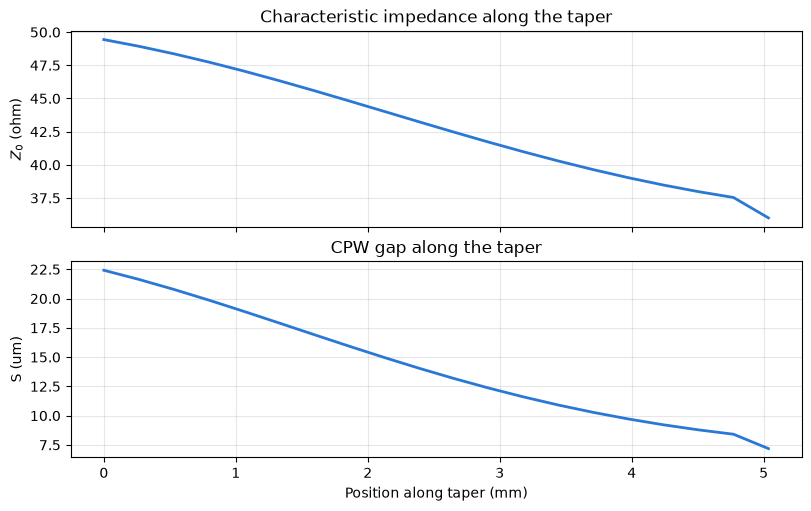

,Start (mm),End (mm),Z0 (ohm),S (um)
Section,,,,
1,0.000,0.252,49.439,22.417
2,0.252,0.504,48.935,21.638
3,0.504,0.755,48.369,20.783
4,0.755,1.007,47.744,19.868
5,1.007,1.259,47.069,18.909
6,1.259,1.511,46.350,17.924
7,1.511,1.763,45.599,16.931
8,1.763,2.014,44.825,15.945
9,2.014,2.266,44.039,14.984


In [4]:
# Klopfenstein Z(x), then invert the CPW model for the gap S(x) at constant W
z_taper = Klopfenstein(med=CPW, param='z0', start=Z1, stop=Z_TARGET, length=L,
                       n_sections=N_SECTIONS, med_kw=cpw_kw, f_kw={'rmax': rmax})
z_profile = z_taper.value_vector
s_profile = np.array([s_of_z0(z) for z in z_profile])
x = np.linspace(0, L, N_SECTIONS)

print(f'Input step: S = {S1*1e6:.2f} -> {s_profile[0]*1e6:.2f} um, Z0 = {Z1:.2f} -> {z_profile[0]:.2f} ohm')
print(f'Output step: S = {s_profile[-2]*1e6:.2f} -> {s_profile[-1]*1e6:.2f} um, Z0 = {z_profile[-2]:.2f} -> {z_profile[-1]:.2f} ohm')

fig, (ax_z, ax_s) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, layout='constrained')
ax_z.plot(x * 1e3, z_profile, color='#2a78d6', linewidth=2)
ax_z.set_ylabel('$Z_0$ (ohm)')
ax_z.set_title('Characteristic impedance along the taper')
ax_s.plot(x * 1e3, s_profile * 1e6, color='#2a78d6', linewidth=2)
ax_s.set_xlabel('Position along taper (mm)')
ax_s.set_ylabel('S (um)')
ax_s.set_title('CPW gap along the taper')
for ax in (ax_z, ax_s):
    ax.grid(alpha=0.3)
plt.show()

# Each section has constant S over length L/N_SECTIONS, as cascaded in the network below
section_edges = np.linspace(0, L, N_SECTIONS + 1)
s_table = pd.DataFrame({
    'Section': np.arange(1, N_SECTIONS + 1),
    'Start (mm)': section_edges[:-1] * 1e3,
    'End (mm)': section_edges[1:] * 1e3,
    'Z0 (ohm)': z_profile,
    'S (um)': s_profile * 1e6,
}).set_index('Section')
display(s_table.round(3))

In [5]:
# Cascade the CPW sections; skrf inserts the impedance steps between them.
s_taper = Taper1D(med=CPW, param='s', start=S1, stop=S2, length=L, n_sections=N_SECTIONS,
                  f=lambda x, length, start, stop: s_profile, f_is_normed=False, med_kw=cpw_kw)
taper = s_taper.network
taper.name = 'Klopfenstein CPW taper'

# Reference the ports to the feed lines. This includes the Klopfenstein end step at port 1.
taper.renormalize([Z1, Z_TARGET])

taper_50 = taper.copy()
taper_50.renormalize([50, Z_TARGET])

In [6]:
# Write the taper as a uSimmics schematic. uSimmics does not document this format, so the
# line layouts are copied from a schematic saved by uSimmics 5.9.
SCH_PATH = Path.home() / '.qucs' / 'CPW_taper_prj' / 'cpw_taper.sch'
SCH_PITCH = 230     # horizontal spacing of the line sections


def sch_components(text):
    block = text.split('<Components>\n')[1].split('</Components>')[0]
    return {line.split()[1]: line for line in block.splitlines() if not line.startswith('GND')}


def sch_props(line):
    return re.findall(r'"([^"]*)"', line)


def set_sch_props(line, new_values):
    parts = re.split(r'"([^"]*)"', line)
    for i, value in new_values.items():
        parts[2 * i + 1] = value
    return ''.join(f'"{p}"' if k % 2 else p for k, p in enumerate(parts))


def usimmics_schematic(s_um, section_um):
    x_cl = [450 + SCH_PITCH * k for k in range(len(s_um))]
    x_p2 = x_cl[-1] + 250
    # SUBST props: er, h, t, tand, rho, D, backside, microstrip models. t = rho = 0 is lossless PEC.
    components = [f'CLIN CL{k + 1} 1 {x} 150 -26 28 0 "Subst1"1"{W*1e6:.9g} um"1"{s:.9g} um"1"{section_um:.9g} um"1"26.85"0'
                  for k, (x, s) in enumerate(zip(x_cl, s_um))]
    components += [
        f'SUBST Subst1 1 520 490 -28 20 0 "{EP_R:.9g}"1"{H*1e6:.9g} um"1"0"1"0"1"0"1"0"0"Air"0"Hammerstad"0"Kirschning"0',
        f'Pac P1 1 220 230 18 -26 0 "1"1"{Z1:.9g} Ω"1"0 dBm"0"1 GHz"0"26.85"0"con_2"0',
        f'Pac P2 1 {x_p2} 230 18 -26 0 "2"1"{Z_TARGET:.9g} Ω"1"0 dBm"0"1 GHz"0"26.85"0"con_2"0',
        'GND * 1 220 260 0 0 0',
        f'GND * 1 {x_p2} 260 0 0 0',
        f'.SP SP1 1 90 490 0 9 0 "lin"1"{freq.start/1e9:.9g} GHz"1"{freq.stop/1e9:.9g} GHz"1"{freq.npoints}"1"no"0"1"0"2"0"none"0',
    ]
    wires = ['220 150 220 200', f'220 150 {x_cl[0] - 30} 150']
    wires += [f'{x + 30} 150 {x + SCH_PITCH - 30} 150' for x in x_cl[:-1]]
    wires += [f'{x_cl[-1] + 30} 150 {x_p2} 150', f'{x_p2} 150 {x_p2} 200']
    return '\n'.join([
        '<QucsStudio Schematic 5.9>', '<Properties>', f'View=0,0,{x_p2 + 110},800,1,0,0', 'Grid=10,10,1',
        'DataSet=*.dat', 'DataDisplay=*.dpl', 'OpenDisplay=1', 'showFrame=0', r'FrameText0=Title \n @PATH@@FILE@',
        'FrameText1=Drawn By:', 'FrameText2=Date: @DATE@', 'FrameText3=Revision:', '</Properties>',
        '<Symbol>', '</Symbol>', '<Components>', *components, '</Components>', '<Wires>', *wires, '</Wires>',
        '<Diagrams>', '</Diagrams>', '<Paintings>', '</Paintings>', '',
    ])


def write_usimmics_taper(path, s_um, section_um):
    new = usimmics_schematic(s_um, section_um)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        path.write_text(new, encoding='utf-8', newline='\n')
        return 'created'

    old = path.read_text(encoding='utf-8')
    old_parts, new_parts = sch_components(old), sch_components(new)
    sections = {name for name in new_parts if name.startswith('CL')}
    if {name for name, line in old_parts.items() if line.startswith('CLIN')} != sections:
        shutil.copy2(path, path.with_name(path.name + '.bak'))
        path.write_text(new, encoding='utf-8', newline='\n')
        return 'regenerated'

    # Same sections: update only S and L so manual edits survive, and report what else differs
    for name in sections:
        s_new, l_new = sch_props(new_parts[name])[2:4]
        old = old.replace(old_parts[name], set_sch_props(old_parts[name], {2: s_new, 3: l_new}))
    path.write_text(old, encoding='utf-8', newline='\n')
    patched_parts = sch_components(old)
    for name, line in new_parts.items():
        if name not in patched_parts or sch_props(patched_parts[name]) != sch_props(line):
            print(f'Not updated, differs from the notebook: {name}')
    return 'patched'


# Line sections are named in chain order; manual rewiring in the GUI is not reflected here.
def usimmics_netlist(text):
    parts = sch_components(text)
    n_lines = sum(line.startswith('CLIN') for line in parts.values())
    lines = ['# uSimmics 5.9', '']
    for name, line in parts.items():
        kind = line.split()[0]
        if kind == 'CLIN':
            nets = f' _net{int(name[2:]) - 1} _net{name[2:]}'
        elif kind == 'Pac':
            nets = ' _net0 gnd' if name == 'P1' else f' _net{n_lines} gnd'
        else:
            nets = ''
        lines.append(f'{kind}:{name}{nets} ' + ' '.join(f'"{v}"' for v in sch_props(line)))
    return '\n'.join(lines) + '\n'


status = write_usimmics_taper(SCH_PATH, s_table['S (um)'].to_numpy(), L / N_SECTIONS * 1e6)
print(f'Schematic {status}: {SCH_PATH}')

Schematic patched: C:\Users\kuksa\.qucs\CPW_taper_prj\cpw_taper.sch


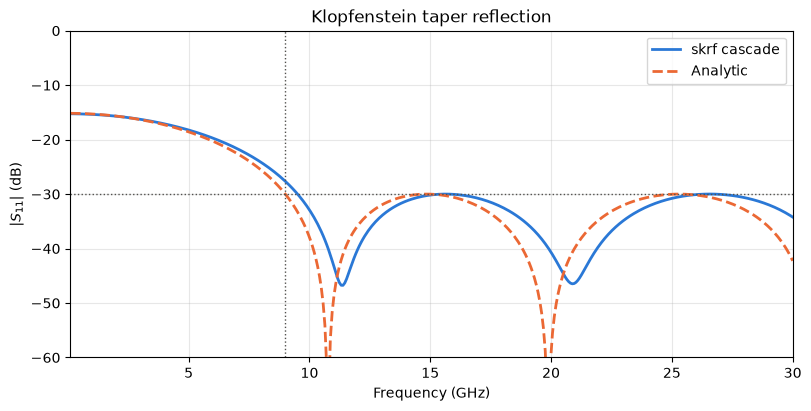

Peak |S11| above F_C: -27.95 dB
Peak |S11| above F_C, port 1 referenced to 50 ohm: -26.30 dB
Min |S21| over sweep: -0.131 dB


In [7]:
# Compare the cascaded network with the analytic Klopfenstein response
beta = 2 * np.pi * freq.f * np.sqrt(ep_eff) / c
gamma_analytic = gamma_0 * np.abs(np.cos(np.sqrt((beta * L)**2 - A**2 + 0j))) / np.cosh(A)

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
taper.plot_s_db(m=0, n=0, ax=ax, color='#2a78d6', linewidth=2, label='skrf cascade')
ax.plot(freq.f, mag_2_db(gamma_analytic), color='#eb6834', linewidth=2, linestyle='--', label='Analytic')
ax.axhline(GAMMA_M_DB, color='#52514e', linewidth=1, linestyle=':')
ax.axvline(F_C, color='#52514e', linewidth=1, linestyle=':')
ax.set_ylim(-60, 0)
ax.set_ylabel('$|S_{11}|$ (dB)')
ax.set_title('Klopfenstein taper reflection')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

passband = freq.f >= F_C
print(f'Peak |S11| above F_C: {mag_2_db(np.abs(taper.s[passband, 0, 0])).max():.2f} dB')
print(f'Peak |S11| above F_C, port 1 referenced to 50 ohm: {mag_2_db(np.abs(taper_50.s[passband, 0, 0])).max():.2f} dB')
print(f'Min |S21| over sweep: {mag_2_db(np.abs(taper.s[:, 1, 0])).min():.3f} dB')

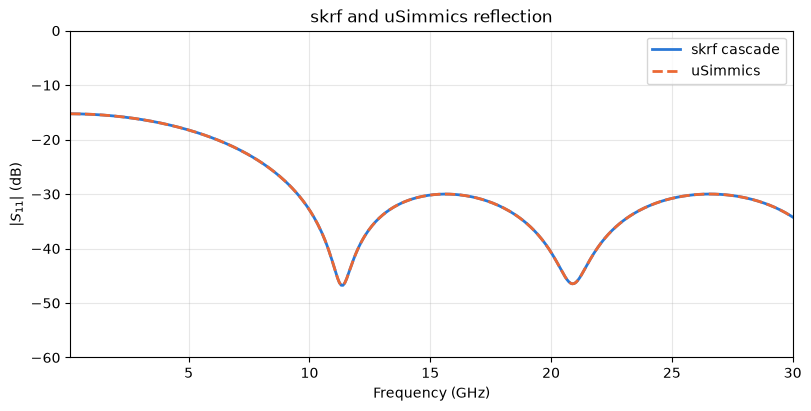

Max |S11 difference|, skrf vs uSimmics: 1.51e-09
Max |S21 difference|, skrf vs uSimmics: 1.79e-09
uSimmics peak |S11| above F_C: -27.95 dB


In [8]:
# Simulate the schematic with the uSimmics engine (no GUI needed) and compare with skrf
USIMMICS_SIM = r'C:\Work\uSimmics\bin\simulator.exe'


def run_usimmics(sch_path):
    netlist = sch_path.with_name(sch_path.stem + '_netlist.txt')
    dataset = sch_path.with_suffix('.dat')
    netlist.write_text(usimmics_netlist(sch_path.read_text(encoding='utf-8')), encoding='utf-8', newline='\n')
    dataset.unlink(missing_ok=True)
    result = subprocess.run([USIMMICS_SIM, str(netlist), str(dataset)], capture_output=True, text=True,
                            stdin=subprocess.DEVNULL)
    if result.returncode != 0:
        raise RuntimeError(f'uSimmics simulation failed: {result.stderr.strip()}')
    return dataset


# Binary dataset layout, inferred from a saved file: 12-byte tag, u32 header size, header,
# then S[n_f] as complex128 for each port pair, then the frequencies as float64.
def read_usimmics_sp(dataset, z0):
    raw = dataset.read_bytes()
    offset = 16 + int.from_bytes(raw[12:16], 'little')
    n_f = (len(raw) - offset) // (4 * 16 + 8)
    s = np.frombuffer(raw, '<c16', 4 * n_f, offset).reshape(2, 2, n_f).transpose(2, 0, 1)
    f = np.frombuffer(raw, '<f8', n_f, offset + 4 * 16 * n_f)
    return rf.Network(frequency=rf.Frequency.from_f(f / 1e9, unit='GHz'), s=s, z0=z0, name='uSimmics')


taper_usimmics = read_usimmics_sp(run_usimmics(SCH_PATH), [Z1, Z_TARGET])

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
taper.plot_s_db(m=0, n=0, ax=ax, color='#2a78d6', linewidth=2, label='skrf cascade')
taper_usimmics.plot_s_db(m=0, n=0, ax=ax, color='#eb6834', linewidth=2, linestyle='--', label='uSimmics')
ax.set_ylim(-60, 0)
ax.set_ylabel('$|S_{11}|$ (dB)')
ax.set_title('skrf and uSimmics reflection')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print(f'Max |S11 difference|, skrf vs uSimmics: {np.abs(taper.s[:, 0, 0] - taper_usimmics.s[:, 0, 0]).max():.2e}')
print(f'Max |S21 difference|, skrf vs uSimmics: {np.abs(taper.s[:, 1, 0] - taper_usimmics.s[:, 1, 0]).max():.2e}')
print(f'uSimmics peak |S11| above F_C: {mag_2_db(np.abs(taper_usimmics.s[passband, 0, 0])).max():.2f} dB')